In [10]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import marching_cubes
from scipy.ndimage import map_coordinates

# ---------------------------------------------------------------
# 1. Wall parameterization
# ---------------------------------------------------------------
Delta = 5.0

def theta_profile(x, Delta=5.0):
    return 2 * np.arctan(np.exp(x / Delta))

wall_types = {
    'bloch':  {'phi': np.pi / 2},
    'neel':   {'phi': 0.0},
    'hybrid': {'phi': np.linspace(-np.pi / 1.1, np.pi / 1.1, 11)}
}

def build_wall_volume(phi_values, x, z):
    """
    Build (Mx, My, Mz) volumes, shape (nz, ny, nx), for a flat 1D wall
    along x: m = (cos(phi) sin(theta(x)), sin(phi) sin(theta(x)), cos(theta(x))).
    phi_values: scalar (constant phi) or 1D array (one phi per z-layer).
    """
    nx, nz = len(x), len(z)
    theta = theta_profile(x, Delta)
    phi_values = np.atleast_1d(phi_values)
    phi_per_z = np.full(nz, phi_values[0]) if len(phi_values) == 1 else phi_values

    Mx = np.zeros((nz, nx)); My = np.zeros((nz, nx)); Mz = np.zeros((nz, nx))
    for iz, phi in enumerate(phi_per_z):
        Mx[iz] = np.cos(phi) * np.sin(theta)[None, :]
        My[iz] = np.sin(phi) * np.sin(theta)[None, :]
        Mz[iz] = np.cos(theta)[None, :]
    return Mx, My, Mz, phi_per_z

# ---------------------------------------------------------------
# 2. Wall geometry extraction (same logic as the main pipeline)
# ---------------------------------------------------------------
def extract_wall_geometry(Mx, My, Mz, spacing=(1.0, 1.0, 1.0)):
    dz, dy, dx = spacing
    verts_phys, faces, normals_phys, _ = marching_cubes(Mz, level=0.0, spacing=spacing)
    verts_idx = verts_phys / np.array([dz, dy, dx])

    def sample(vol, pts_idx):
        return map_coordinates(vol, pts_idx.T, order=1, mode='nearest')

    M_v = np.stack([sample(Mx, verts_idx), sample(My, verts_idx), sample(Mz, verts_idx)], axis=1)

    eps_idx = 1.0 / np.array([dz, dy, dx])
    step = normals_phys * eps_idx
    flip = sample(Mz, verts_idx + step) < sample(Mz, verts_idx - step)
    normals_phys[flip] *= -1

    return verts_phys[:, ::-1], faces, normals_phys[:, ::-1], M_v  # reorder to (x,y,z)

def compute_wall_angles(M_v, normals_xyz, up_axis=np.array([0.0, 0.0, 1.0])):
    M_n = np.einsum('ij,ij->i', M_v, normals_xyz)
    M_t_vec = M_v - M_n[:, None] * normals_xyz
    psi_unsigned = np.degrees(np.arctan2(np.linalg.norm(M_t_vec, axis=1), M_n))  # 0/180=Neel, 90=Bloch

    t_vec = np.cross(np.broadcast_to(up_axis, normals_xyz.shape), normals_xyz)
    t_hat = t_vec / np.linalg.norm(t_vec, axis=1, keepdims=True)
    M_t_signed = np.einsum('ij,ij->i', M_v, t_hat)
    psi_chiral = np.degrees(np.arctan2(M_t_signed, M_n))  # signed, carries chirality

    return psi_unsigned, psi_chiral, t_hat

# ---------------------------------------------------------------
# 3. Run each wall type and verify against analytic predictions
# ---------------------------------------------------------------
x = np.linspace(-6 * Delta, 6 * Delta, 121)
z = np.linspace(0, 4, 5)

results = {}
for name, params in wall_types.items():
    Mx, My, Mz, phi_per_z = build_wall_volume(params['phi'], x, z)
    verts_xyz, faces, normals_xyz, M_v = extract_wall_geometry(Mx, My, Mz)
    psi_unsigned, psi_chiral, t_hat = compute_wall_angles(M_v, normals_xyz)
    results[name] = dict(Mx=Mx, My=My, Mz=Mz, x=x, y=y, phi_per_z=phi_per_z,
                          verts_xyz=verts_xyz, normals_xyz=normals_xyz, M_v=M_v,
                          psi_unsigned=psi_unsigned, psi_chiral=psi_chiral)

print("=== Verification ===")
for name, r in results.items():
    n_mean = r['normals_xyz'].mean(axis=0)
    print(f"\n[{name}] mean normal (x,y,z) = {np.round(n_mean, 4)} "
          f"(expect ~(-1, 0, 0))")
    assert np.allclose(np.abs(n_mean), [1, 0, 0], atol=0.05), "normal not purely along x!"

n_bloch = np.degrees(np.mean(results['bloch']['psi_unsigned']))
n_neel = np.degrees(np.mean(results['neel']['psi_unsigned'])) if False else np.mean(results['neel']['psi_unsigned'])
print(f"\n[bloch] mean psi_unsigned = {np.mean(results['bloch']['psi_unsigned']):.2f} deg (expect ~90)")
print(f"[neel]  mean psi_unsigned = {np.mean(results['neel']['psi_unsigned']):.2f} deg (expect ~180)")
assert np.allclose(np.mean(results['bloch']['psi_unsigned']), 90, atol=2)
assert np.allclose(np.mean(results['neel']['psi_unsigned']), 180, atol=2)

print(f"\n[bloch] mean psi_chiral = {np.mean(results['bloch']['psi_chiral']):.2f} deg (expect ~-90)")
print(f"[neel]  mean psi_chiral = {np.mean(results['neel']['psi_chiral']):.2f} deg (expect ~180)")
assert np.allclose(np.mean(results['bloch']['psi_chiral']), -90, atol=2)
assert np.allclose(np.mean(results['neel']['psi_chiral']), 180, atol=2)

# Hybrid: bin computed psi_chiral by which z-layer each vertex came from,
# compare to predicted phi_input + 180 deg (wrapped to (-180, 180])
r = results['hybrid']
z_idx = np.round(r['verts_xyz'][:, 2]).astype(int)
phi_deg = np.degrees(r['phi_per_z'])
predicted = (phi_deg + 180 + 180) % 360 - 180  # wrap to (-180, 180]

measured_per_layer = np.array([np.mean(r['psi_chiral'][z_idx == iz]) for iz in range(len(phi_deg))])
print("\n[hybrid] layer-by-layer check (measured vs predicted phi+180, deg):")
for iz in range(len(phi_deg)):
    print(f"  z={iz:2d}  phi_in={phi_deg[iz]:7.2f}  measured={measured_per_layer[iz]:7.2f}  "
          f"predicted={predicted[iz]:7.2f}")
assert np.allclose(measured_per_layer, predicted, atol=2)
print("\nAll checks passed.")

ValueError: Input volume should be a 3D numpy array.

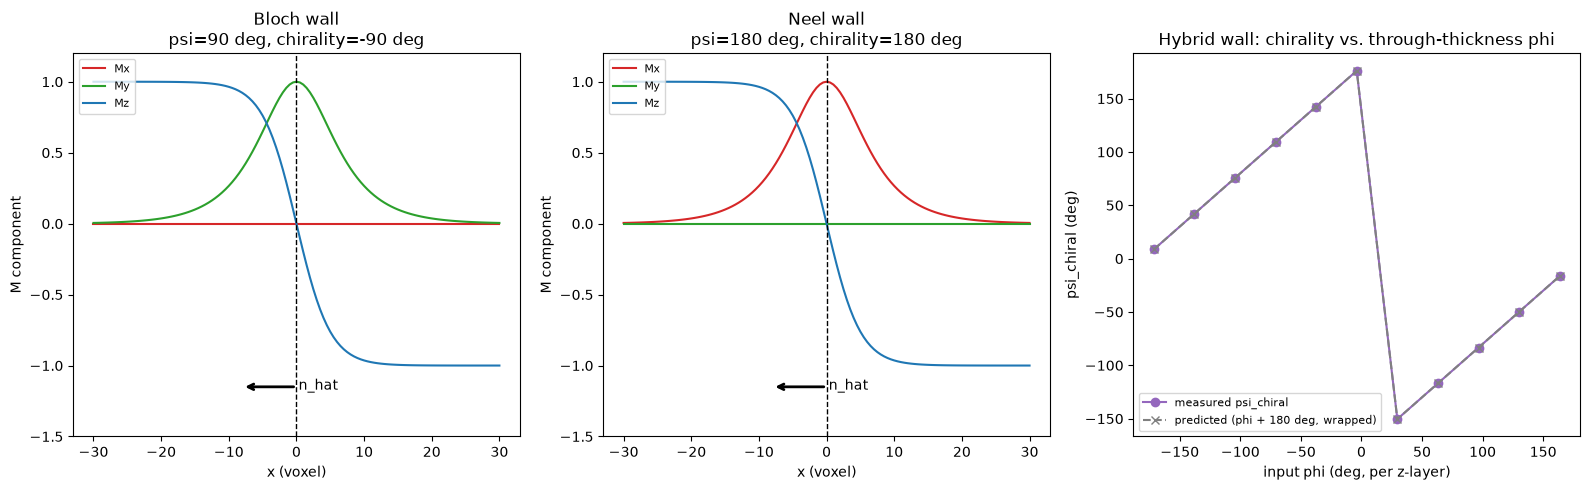

In [9]:
# ---------------------------------------------------------------
# 4. Figure: one panel per wall type
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, name in zip(axes[:2], ['bloch', 'neel']):
    r = results[name]
    ax.plot(r['x'], r['Mx'][0, 0, :], label='Mx', color='tab:red')
    ax.plot(r['x'], r['My'][0, 0, :], label='My', color='tab:green')
    ax.plot(r['x'], r['Mz'][0, 0, :], label='Mz', color='tab:blue')
    ax.axvline(0, color='k', ls='--', lw=1)
    n = r['normals_xyz'].mean(axis=0)
    ax.annotate('', xy=(n[0] * 8, -1.15), xytext=(0, -1.15),
                arrowprops=dict(arrowstyle='->', color='black', lw=2))
    ax.text(3.2, -1.17, 'n_hat', ha='center')
    ax.set_title(f"{name.capitalize()} wall\n"
                 f"psi={np.mean(r['psi_unsigned']):.0f} deg, "
                 f"chirality={np.mean(r['psi_chiral']):.0f} deg")
    ax.set_xlabel('x (voxel)')
    ax.set_ylabel('M component')
    ax.set_ylim(-1.5, 1.2)
    ax.legend(loc='upper left', fontsize=8)

ax = axes[2]
r = results['hybrid']
ax.plot(phi_deg, measured_per_layer, 'o-', color='tab:purple', label='measured psi_chiral')
ax.plot(phi_deg, predicted, 'x--', color='gray', label='predicted (phi + 180 deg, wrapped)')
ax.set_xlabel('input phi (deg, per z-layer)')
ax.set_ylabel('psi_chiral (deg)')
ax.set_title('Hybrid wall: chirality vs. through-thickness phi')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

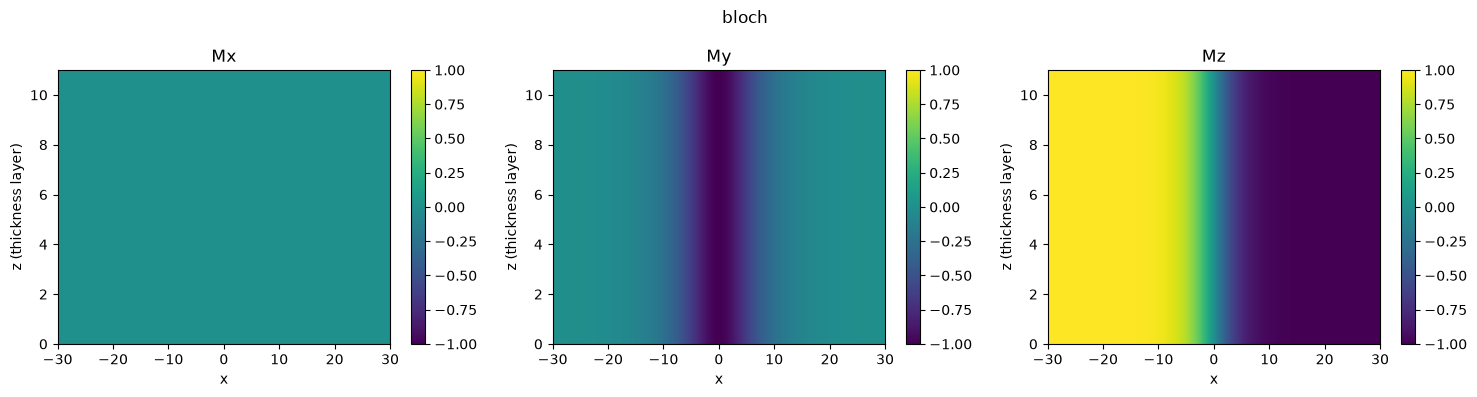

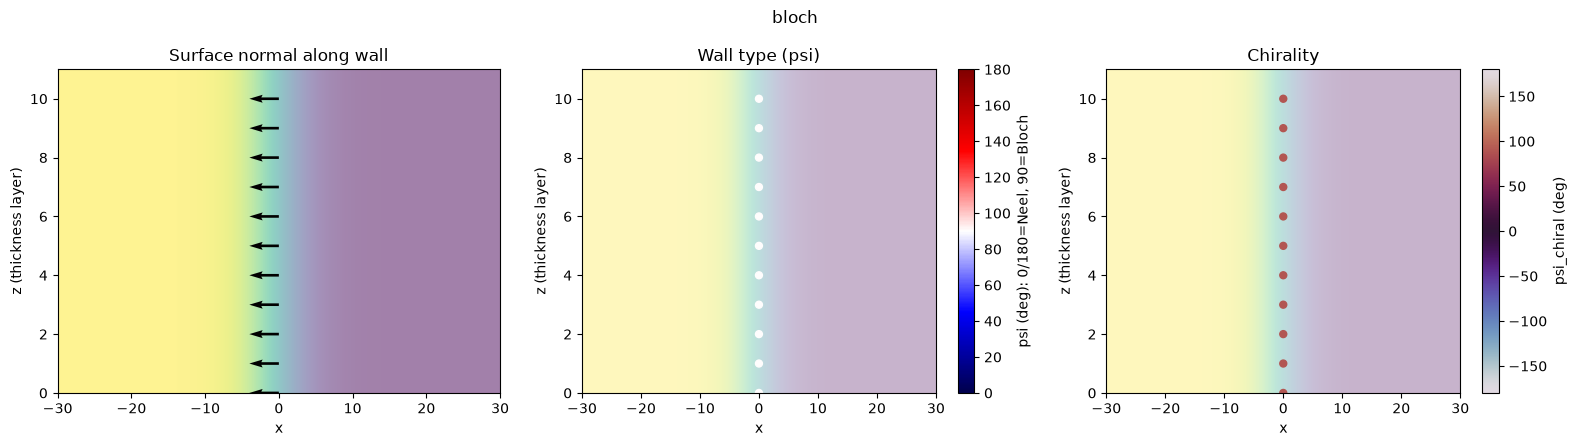

[bloch] mean psi_unsigned = 90.0 deg, mean psi_chiral = 90.0 deg


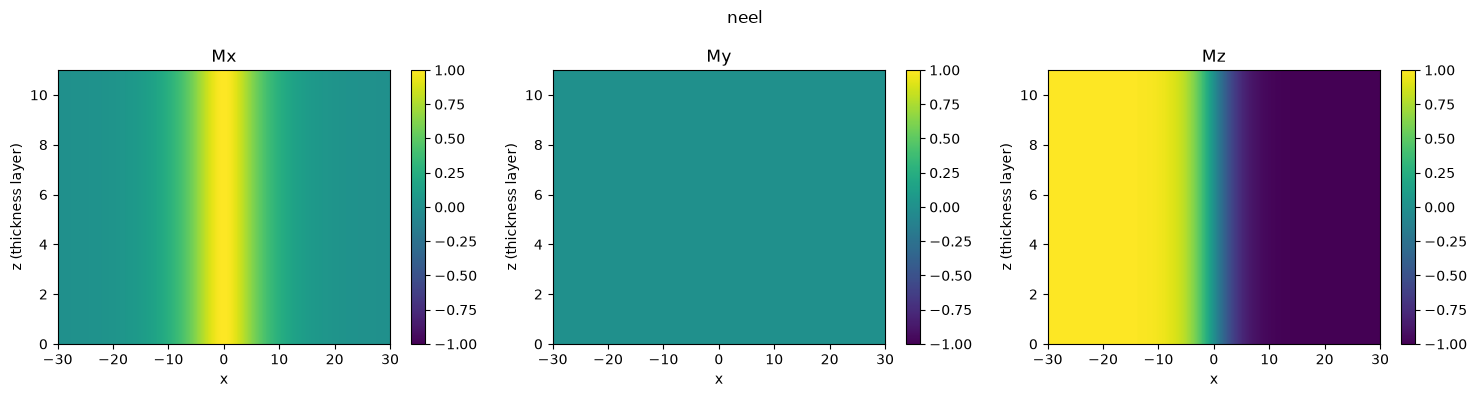

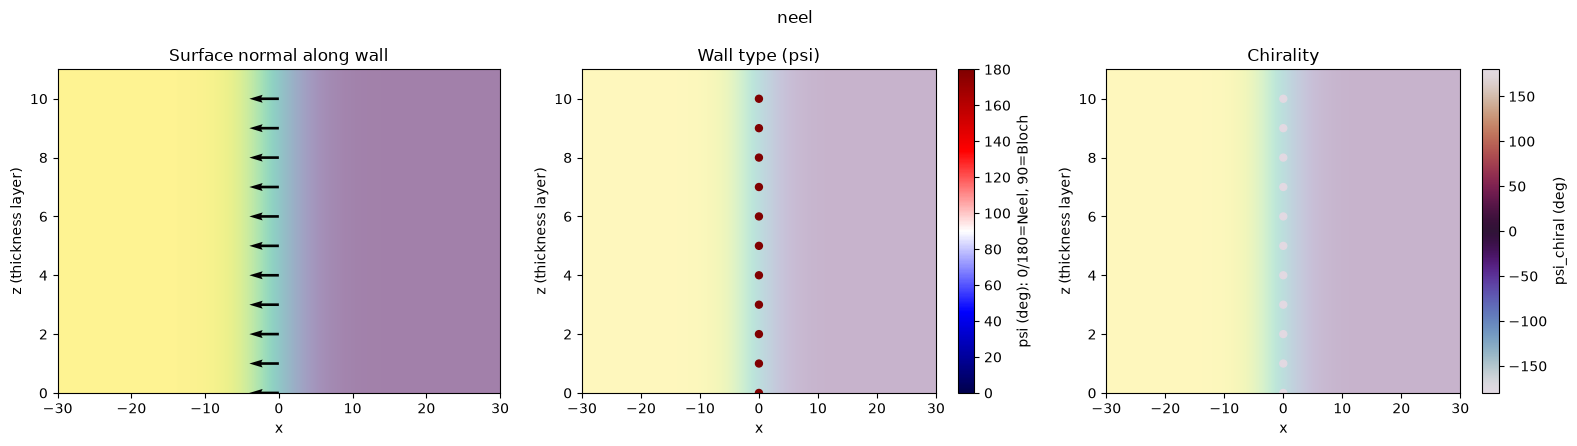

[neel] mean psi_unsigned = 180.0 deg, mean psi_chiral = 180.0 deg


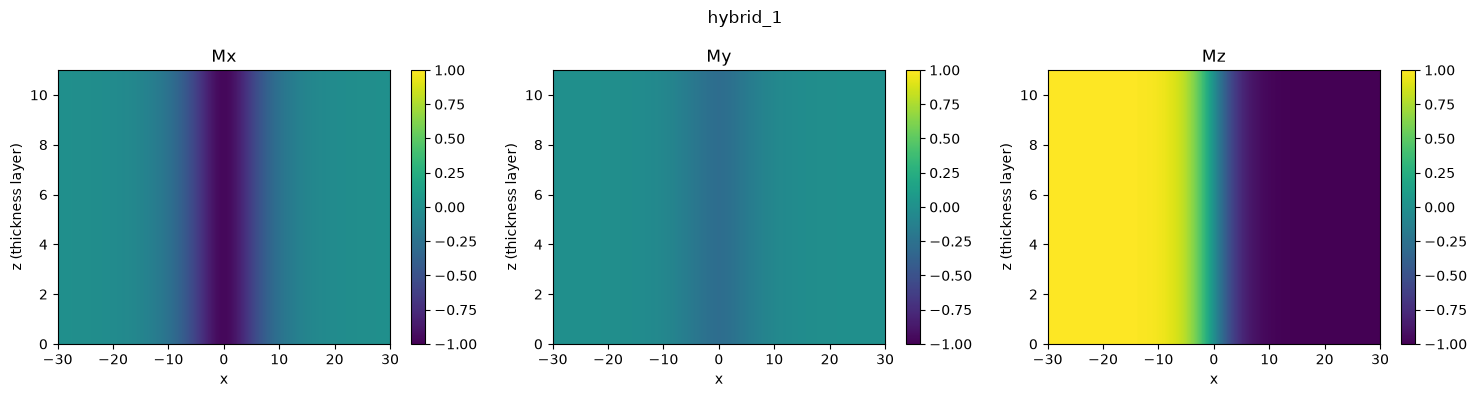

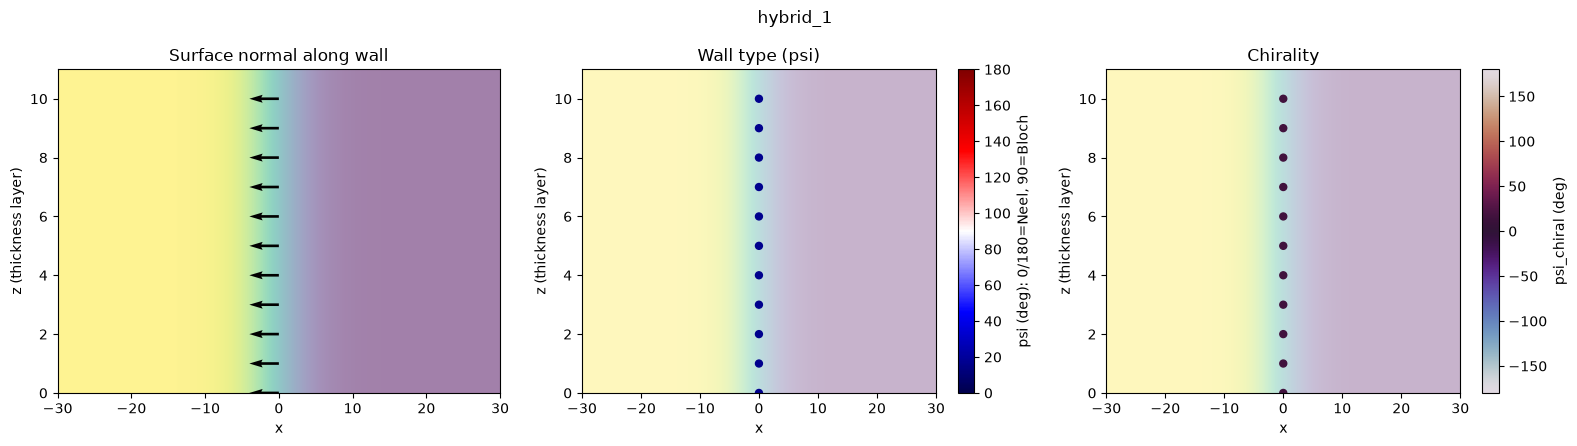

[hybrid_1] mean psi_unsigned = 16.4 deg, mean psi_chiral = 16.4 deg


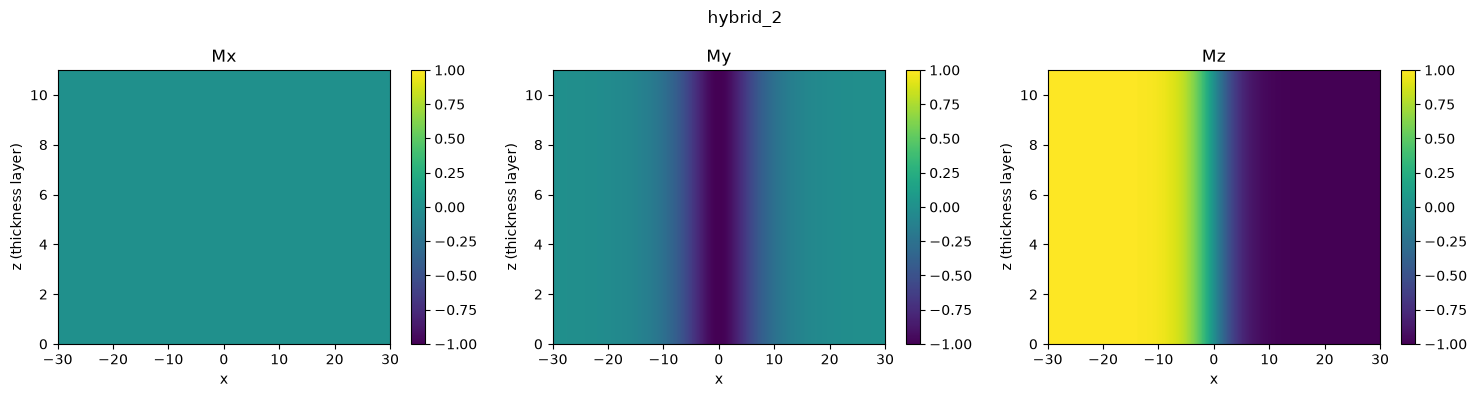

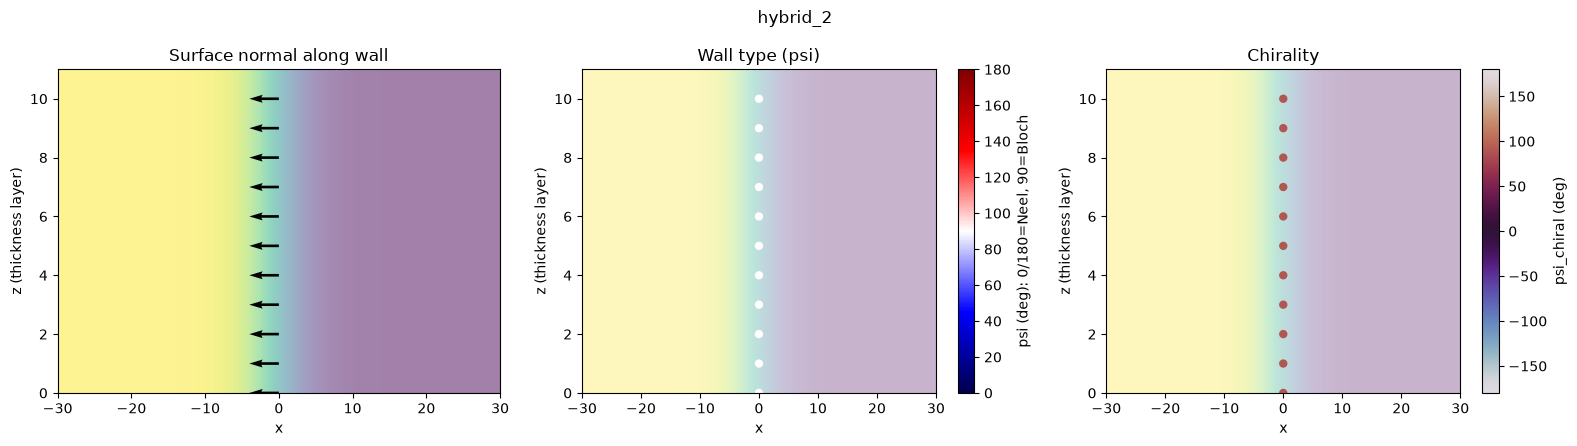

[hybrid_2] mean psi_unsigned = 90.0 deg, mean psi_chiral = 90.0 deg


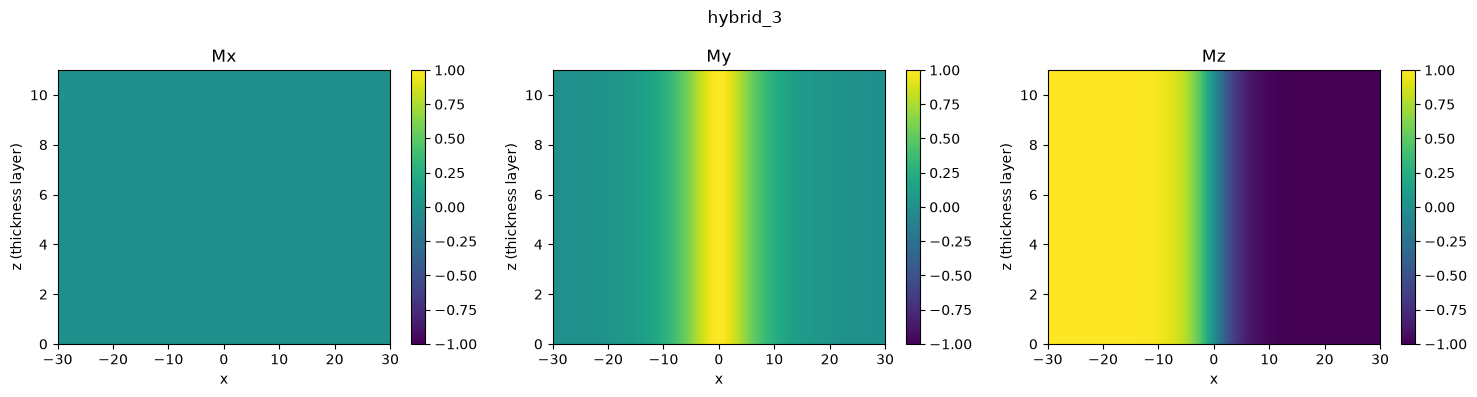

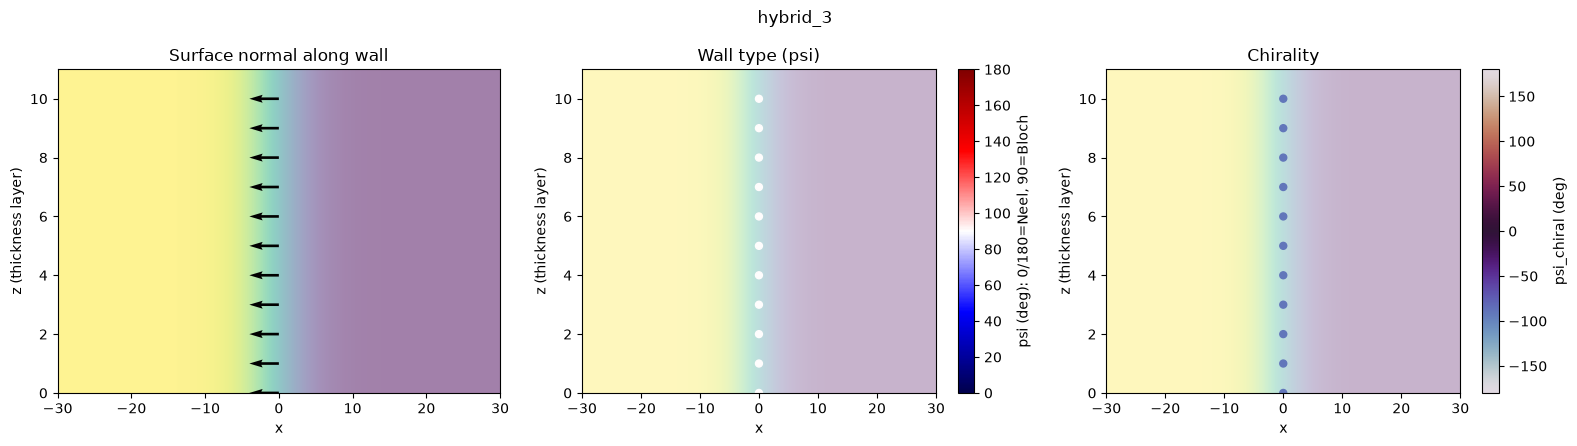

[hybrid_3] mean psi_unsigned = 90.0 deg, mean psi_chiral = -90.0 deg


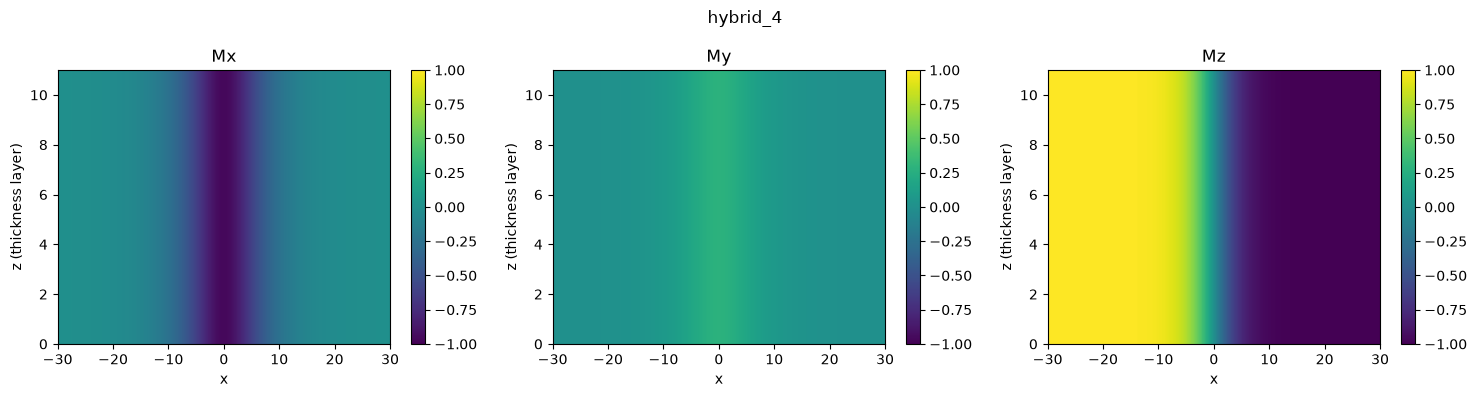

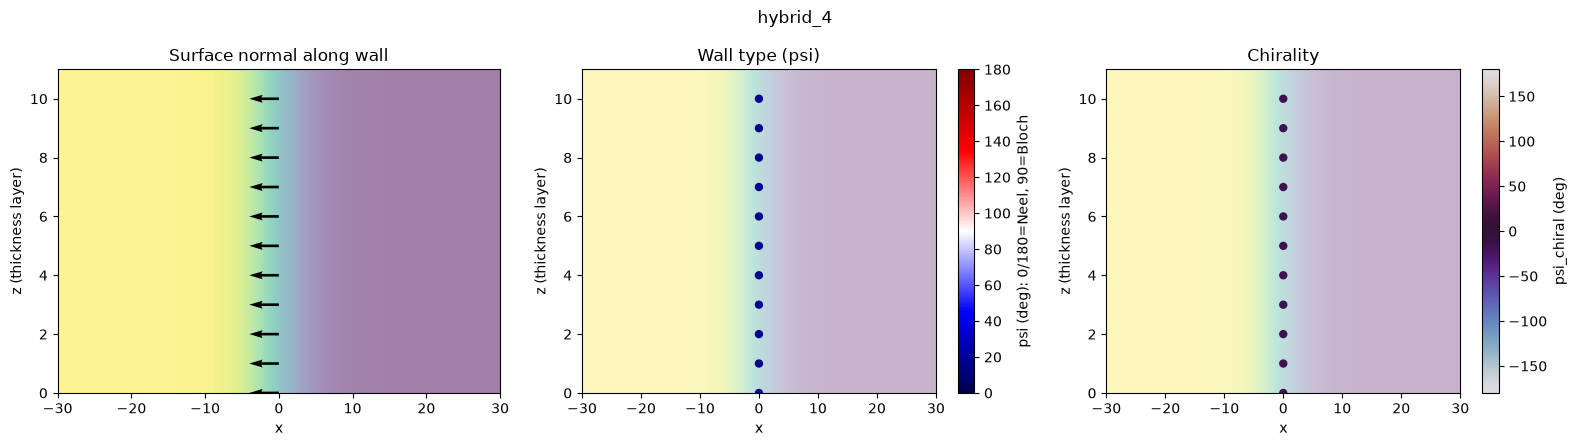

[hybrid_4] mean psi_unsigned = 16.4 deg, mean psi_chiral = -16.4 deg


In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from skimage.measure import find_contours
from scipy.ndimage import map_coordinates, gaussian_filter

# ---------------------------------------------------------------
# 1. Wall parameterization
# ---------------------------------------------------------------
def theta_profile(x, Delta=5.0):
    return 2 * np.arctan(np.exp(x / Delta))

wall_types = {
    'bloch':  {'phi': -np.pi / 2},
    'neel':   {'phi': 0.0},
}

def build_wall_2d(phi_values, x, Delta=5.0):
    """
    Build a 2D (nz, nx) wall: x = in-plane, across-wall coordinate;
    z = through-thickness coordinate (film depth), along which phi
    can vary (for the hybrid case, modeling e.g. Neel caps / Bloch core).
    """
    phi_values = np.atleast_1d(phi_values)
    nz = len(phi_values) if len(phi_values) > 1 else 11
    phi_per_z = np.full(nz, phi_values[0]) if len(phi_values) == 1 else phi_values

    theta = theta_profile(x, Delta)  # (nx,)
    Mx = np.zeros((nz, len(x))); My = np.zeros_like(Mx); Mz = np.zeros_like(Mx)
    for iz, phi in enumerate(phi_per_z):
        Mx[iz] = np.cos(phi) * np.sin(theta)
        My[iz] = np.sin(phi) * np.sin(theta)
        Mz[iz] = np.cos(theta)
    return Mx, My, Mz, phi_per_z

# ---------------------------------------------------------------
# 2. Extract the wall contour, normal, M, in 2D
# ---------------------------------------------------------------
def extract_wall_geometry_2d(Mx, My, Mz, spacing=(1.0, 1.0)):
    """
    spacing = (dz, dx), physical size of one grid step along each axis.
    Returns per-contour-point: physical (x, z) position, 3-component
    normal (nx, 0, nz) embedded in 3D, and 3-component M = (Mx, My, Mz).
    """
    dz, dx = spacing
    contours = find_contours(Mz, level=0.0)
    contour = max(contours, key=len)          # (row=z_idx, col=x_idx), fractional
    pts_idx = contour                          # shape (N, 2) -> (z_idx, x_idx)

    def sample(vol, pts):
        return map_coordinates(vol, pts.T, order=1, mode='nearest')

    # Gradient of Mz gives the (unnormalized) normal direction
    gz, gx = np.gradient(Mz, dz, dx)
    n_z = sample(gz, pts_idx)
    n_x = sample(gx, pts_idx)
    n_mag = np.sqrt(n_x**2 + n_z**2)
    n_x, n_z = n_x / n_mag, n_z / n_mag

    # Sign-correct: normal should point from -Mz into +Mz
    eps = 1.0
    fwd = np.stack([pts_idx[:, 0] + eps * n_z / dz, pts_idx[:, 1] + eps * n_x / dx], axis=1)
    bwd = np.stack([pts_idx[:, 0] - eps * n_z / dz, pts_idx[:, 1] - eps * n_x / dx], axis=1)
    flip = sample(Mz, fwd) < sample(Mz, bwd)
    n_x[flip] *= -1
    n_z[flip] *= -1

    normals_xyz = np.stack([n_x, np.zeros_like(n_x), n_z], axis=1)  # embed in (x,y,z)

    M_v = np.stack([sample(Mx, pts_idx), sample(My, pts_idx), sample(Mz, pts_idx)], axis=1)

    x_phys = pts_idx[:, 1] * dx
    z_phys = pts_idx[:, 0] * dz

    return x_phys, z_phys, normals_xyz, M_v

# ---------------------------------------------------------------
# 3. Angle computation (unchanged from the 3D case)
# ---------------------------------------------------------------
def compute_wall_angles(M_v, normals_xyz, up_axis=np.array([0.0, 0.0, 1.0])):
    M_n = np.einsum('ij,ij->i', M_v, normals_xyz)
    M_t_vec = M_v - M_n[:, None] * normals_xyz
    psi_unsigned = np.degrees(np.arctan2(np.linalg.norm(M_t_vec, axis=1), M_n))

    t_vec = np.cross(np.broadcast_to(up_axis, normals_xyz.shape), normals_xyz)
    t_hat = t_vec / np.linalg.norm(t_vec, axis=1, keepdims=True)
    M_t_signed = np.einsum('ij,ij->i', M_v, t_hat)
    psi_chiral = np.degrees(np.arctan2(M_t_signed, M_n))

    return psi_unsigned, psi_chiral, t_hat

# ---------------------------------------------------------------
# 4. Plotting: raw components
# ---------------------------------------------------------------
def plot_raw_components_2d(x, Mx, My, Mz, title=''):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    extent = [x.min(), x.max(), 0, Mz.shape[0]]
    for ax, data, label in zip(axes, [Mx, My, Mz], ['Mx', 'My', 'Mz']):
        im = ax.imshow(data, origin='lower', extent=extent, aspect='auto',
                        cmap='viridis', vmin=-1, vmax=1)
        ax.set_title(label)
        ax.set_xlabel('x')
        ax.set_ylabel('z (thickness layer)')
        fig.colorbar(im, ax=ax)
    fig.suptitle(f"{title}")
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------
# 5. Plotting: overlay of normal, psi, chirality on the wall
# ---------------------------------------------------------------
def plot_wall_overlay_2d(x, Mz, x_wall, z_wall, normals_xyz, psi_unsigned, psi_chiral, title=''):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    extent = [x.min(), x.max(), 0, Mz.shape[0]]

    x_wall_use = x_wall - 120

    # Panel 1: normal vectors along the wall
    ax = axes[0]
    ax.imshow(Mz, origin='lower', extent=extent, aspect='auto', cmap='viridis',
              vmin=-1, vmax=1, alpha=0.5)
    ax.quiver(x_wall_use, z_wall, normals_xyz[:, 0], normals_xyz[:, 2],
              color='k', scale=15, width=0.006)
    ax.set_title('Surface normal along wall')
    ax.set_xlabel('x'); ax.set_ylabel('z (thickness layer)')

    # Panel 2: psi (unsigned wall type: 0/180=Neel, 90=Bloch)
    ax = axes[1]
    ax.imshow(Mz, origin='lower', extent=extent, aspect='auto', cmap='viridis',
              vmin=-1, vmax=1, alpha=0.3)
    sc = ax.scatter(x_wall_use, z_wall, c=psi_unsigned, cmap='seismic', vmin=0, vmax=180, s=25)
    fig.colorbar(sc, ax=ax, label='psi (deg): 0/180=Neel, 90=Bloch')
    ax.set_title('Wall type (psi)')
    ax.set_xlabel('x'); ax.set_ylabel('z (thickness layer)')

    # Panel 3: chirality (signed, cyclic)
    ax = axes[2]
    ax.imshow(Mz, origin='lower', extent=extent, aspect='auto', cmap='viridis',
              vmin=-1, vmax=1, alpha=0.3)
    sc = ax.scatter(x_wall_use, z_wall, c=psi_chiral, cmap='twilight', vmin=-180, vmax=180, s=25)
    fig.colorbar(sc, ax=ax, label='psi_chiral (deg)')
    ax.set_title('Chirality')
    ax.set_xlabel('x'); ax.set_ylabel('z (thickness layer)')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------
# 6. Run for each wall type
# ---------------------------------------------------------------
Delta = 5.0
x = np.linspace(-6 * Delta, 6 * Delta, 241)

for name, params in wall_types.items():
    Mx, My, Mz, phi_per_z = build_wall_2d(params['phi'], x, Delta)
    x_wall, z_wall, normals_xyz, M_v = extract_wall_geometry_2d(Mx, My, Mz)
    psi_unsigned, psi_chiral, t_hat = compute_wall_angles(M_v, normals_xyz)

    plot_raw_components_2d(x, Mx, My, Mz, title=name)
    plot_wall_overlay_2d(x, Mz, x_wall, z_wall, normals_xyz, psi_unsigned, psi_chiral, title=name)

    print(f"[{name}] mean psi_unsigned = {psi_unsigned.mean():.1f} deg, "
          f"mean psi_chiral = {psi_chiral.mean():.1f} deg")

hybrid_wall_types = {
    'hybrid_1':  {'phi': -np.pi / 1.1},
    'hybrid_2':   {'phi': -np.pi / 2},
    'hybrid_3':   {'phi': np.pi / 2},
    'hybrid_4': {'phi': np.pi / 1.1}
}

for name, params in hybrid_wall_types.items():
    Mx, My, Mz, phi_per_z = build_wall_2d(params['phi'], x, Delta)
    x_wall, z_wall, normals_xyz, M_v = extract_wall_geometry_2d(Mx, My, Mz)
    psi_unsigned, psi_chiral, t_hat = compute_wall_angles(M_v, normals_xyz)

    plot_raw_components_2d(x, Mx, My, Mz, title=name)
    plot_wall_overlay_2d(x, Mz, x_wall, z_wall, normals_xyz, psi_unsigned, psi_chiral, title=name)

    print(f"[{name}] mean psi_unsigned = {psi_unsigned.mean():.1f} deg, "
          f"mean psi_chiral = {psi_chiral.mean():.1f} deg")